# tp3d event display, coloured by MC particle

Set the file, the event and the TP algorithm in the **Settings** cell and run all cells. It shows

1. the particles with supported 3D points (table),
2. the interactive 3D view (rotate, zoom; click a legend entry to hide or show it; the unsupported
   points are hidden by default),
3. the z-y, z-x and x-y projections of the whole detector, and zoomed on the event.

Each point is coloured by the MC particle (|trackID|) with most of the energy in its collection TP;
the same particle has the same colour in all views. The reconstruction is truth-free, truth only
gives the colours. The functions are in `event_display.py` (same folder), which also runs from the
command line: `python event_display.py FILE.h5 EVENT` writes the same plots into a folder
`<file name>_ev<EVENT>/`. Set `SAVE = True` below to write them from here too.

In [1]:
# Imports

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.graph_objects as go

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import event_display as ed  # noqa: E402

pd.set_option("display.width", 200)

In [2]:
# Settings

FILE = HERE.parent / "data" / "AtmCosRad" / "21373" / "AtmCosRad_FullSimTP_dune10kt_1x2x6_N50_021373_000001.h5"
EVENT = 3
DATASET = "tpmakerTPCabsRS"         # or "tpmakerTPCsimpleThr"
SAVE = False                        # True: also write the HTML / PNG / CSV into <file name>_ev<EVENT>/

In [3]:
# Reconstruct the event and list its particles (supported points, ADC, 3-plane points)

p, mc, nu_text, shown = ed.reconstruct_event(FILE, EVENT, DATASET)
title = (f"{Path(FILE).name}  event {EVENT}  {DATASET}" + (f"  |  {nu_text}" if nu_text else "")
         + f"  (tp3d v5, collection adc >= {ed.tp3d.ADC_CUT_X.get(DATASET)})")
print(title)
print(f"{len(p)} points, {int(p.support.sum())} supported")
ed.particle_table(p, mc).head(20)

AtmCosRad_FullSimTP_dune10kt_1x2x6_N50_021373_000001.h5  event 3  tpmakerTPCabsRS  |  nu_mu 1.98 GeV CC DIS  (tp3d v5, collection adc >= 3100)
427 points, 216 supported


,points,adc,three_plane,particle
tid,,,,
32755,100,946938.0,98,"pi+ E_tot 1.31 GeV, atmospherics primary (ID 3..."
35275,13,829495.0,6,"p E_tot 1.07 GeV, atmospherics secondary (ID 3..."
32754,17,786196.0,8,"p E_tot 1.22 GeV, atmospherics primary (ID 32754)"
32753,10,293442.0,5,"mu- E_tot 0.157 GeV, atmospherics primary (ID ..."
-1,49,261437.0,46,radiological
35439,5,192094.0,3,"e- E_tot 0.0236 GeV, atmospherics secondary (I..."
35283,2,86369.0,1,"Ar36 E_tot 33.5 GeV, atmospherics secondary (I..."
35279,2,45705.0,2,"gamma E_tot 0.00474 GeV, atmospherics secondar..."
32963,2,32599.0,2,"gamma E_tot 0.00452 GeV, atmospherics secondar..."


## 3D view

Axes: x is the drift coordinate (APA at x = 0), z along the detector, y the height. The box is the
active volume of the 1x2x6 geometry, the grey frame the APA plane with the APA boundaries. Hover a
point for its particle (PDG, generator, total initial energy, primary or secondary, neutrino
interaction for atmospherics), channel, ADC and number of planes.

In [4]:
fig3d = go.Figure(ed.figure_3d(p, mc, title))
fig3d.update_layout(height=800)
fig3d.show()

## Projections, whole detector

z-y: the detector seen along the drift direction (the APA face); z-x: from above; x-y: along z.
Vertical grey lines in z are the APA boundaries, the darker line at x = 0 the APA plane.

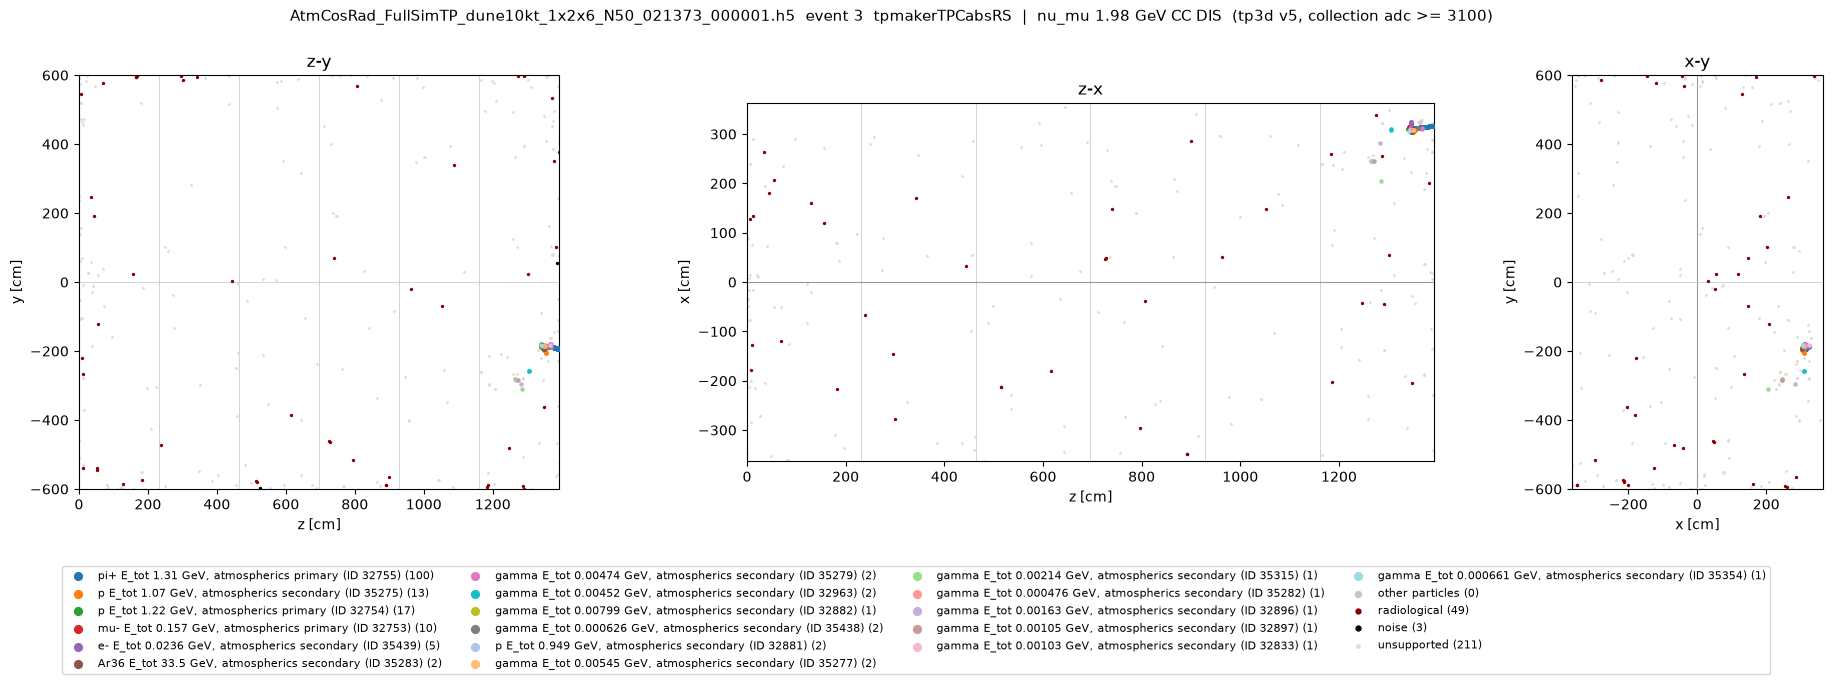

In [5]:
fig = ed.figure_views(p, mc, title, zoom=False)
plt.show()

## Projections, zoomed on the event

The same, limited to the signal points (not radiologicals or noise) with a 30 cm margin.

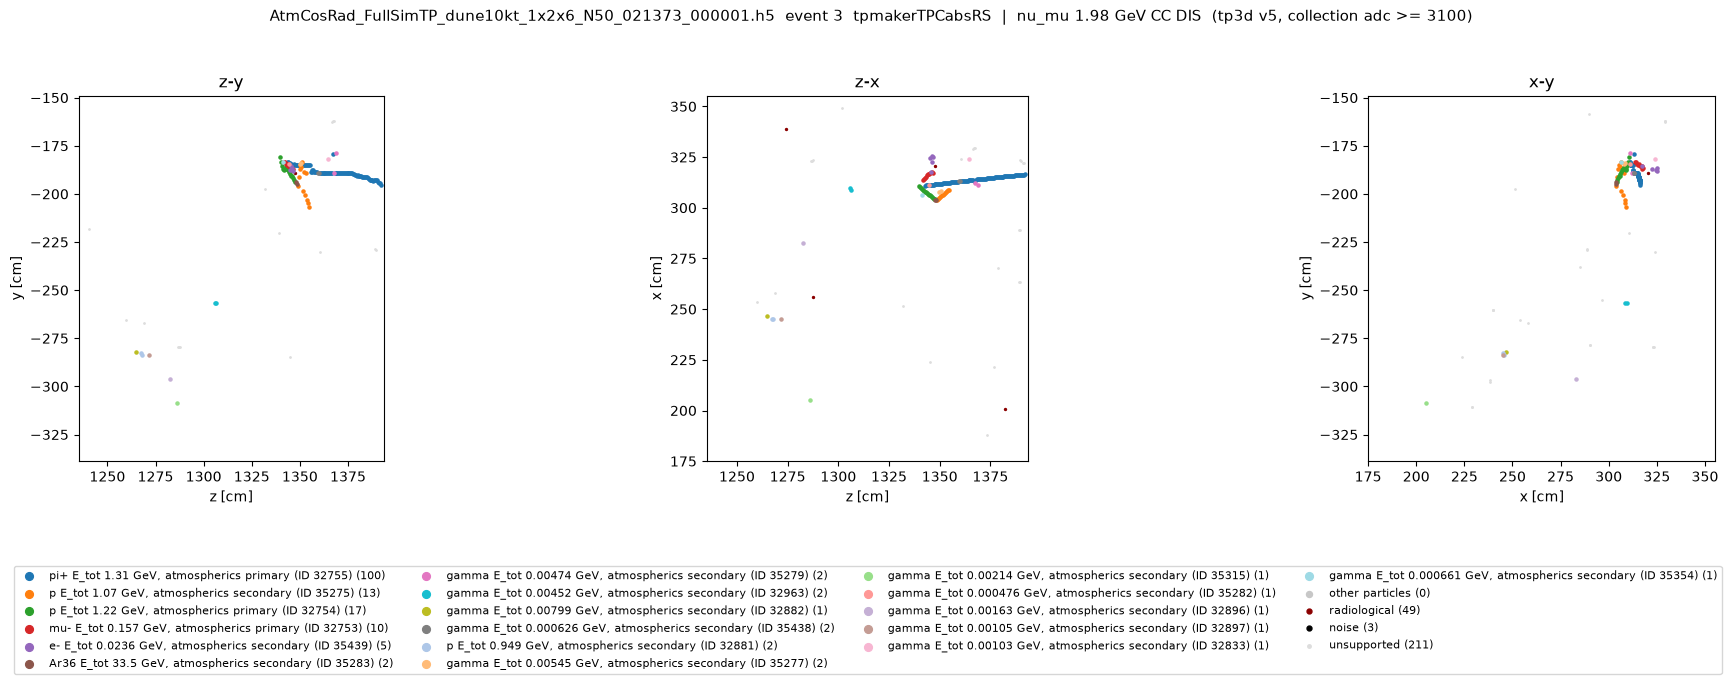

In [6]:
fig = ed.figure_views(p, mc, title, zoom=True)
plt.show()

In [7]:
# Save the plots (same output as the script)

if SAVE:
    outdir = HERE / f"{Path(FILE).stem}_ev{EVENT}"
    ed.make(FILE, EVENT, DATASET, outdir)
    print("wrote", outdir)